# SPOC vs TESSCut Aperture / Crowding Control

This notebook reruns the crowding analysis on corrected baseline feature pairs. Both products must have successful feature extraction and at least 100 finite cadences. The 39 predictors, seed-42 split, and 500-tree class-balanced Random Forest settings match the controlled baseline.

Only the completed Gaia neighborhood catalog is reused; derived predictions, quartiles, and feature-distance statistics are recomputed. Failed or incomplete Gaia queries leave crowding values missing without excluding an otherwise eligible star from the matched classifier. Results test association rather than causality: Gaia G-band crowding and area-equivalent aperture size are proxies, not calibrated TESS contamination fractions.

All counts, metrics, and conclusions must be read from the new execution outputs. Previous manuscript values are not assumed.


## 1. Configuration

The analysis uses:

- Gaia search radius: **84 arcsec (~4 TESS pixels)**
- TESS pixel scale approximation: **21 arcsec/pixel**
- Gaia target-match radius: **2 arcsec**
- Gaia G magnitude limit: **20.5**
- Gaia batch size: **50 targets**
- local worker count: **24**

Local per-star aperture calculations and crowding-metric summaries use multithreading. Gaia TAP batches remain sequential because they share one transient upload file and use an external asynchronous service. The Gaia stage is restartable through its cumulative parquet cache.

In [1]:
from __future__ import annotations

import json
import tess_research_validation as trv
import math
import os
import time
import traceback
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, mannwhitneyu

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

Project_Root = Path(os.environ.get("Project_Root", "/data/projects/TESS_Research_Publication"))
DATA_ROOT = Project_Root / "data"

SPOC_TESSCut_META_CONSOLIDATE_FILE_QC = (
    DATA_ROOT / "SPOC_TESSCutCache" / "SPOC_TESSCut_Metadata_Consolidated_QC.parquet"
)

# Existing controlled feature table used by the SPOC-vs-TESSCut RF experiment.
SPOC_TESSCut_FEATURE_FILE_QC = (
    DATA_ROOT / "SPOC_TESSCutCache" / "SPOC_TESSCut_features_QC.parquet"
)

GAIA_CACHE_DIR = Project_Root / "data" / "external_cache" / "gaia" / "spoc"

OUTPUT_DIR = Project_Root / "results" / "crowding" / "spoc"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GAIA_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Single cumulative Gaia query parquet used for both progress tracking
# and Gaia source rows. No new per-batch parquet cache files are created.
TARGET_TABLE_FILE = GAIA_CACHE_DIR / "unique_targets.parquet"
GAIA_NEIGHBORS_FILE = GAIA_CACHE_DIR / "gaia_neighbors.parquet"

# Read-only legacy location from the previous implementation.
# It is used only once to recover already completed work if the new
# cumulative parquet does not yet exist.
LEGACY_GAIA_BATCH_DIR = GAIA_CACHE_DIR / "gaia_batches"

# One transient upload file, overwritten for each Gaia request.
GAIA_UPLOAD_TEMP_FILE = GAIA_CACHE_DIR / "_gaia_upload_current.xml"
CROWDING_METRICS_FILE = OUTPUT_DIR / "crowding_metrics.parquet"
RF_TEST_RESULTS_FILE = OUTPUT_DIR / "rf_test_predictions_with_crowding.parquet"

TESS_PIXEL_SCALE_ARCSEC = 21.0
GAIA_QUERY_RADIUS_ARCSEC = 84.0
GAIA_G_MAX = 20.5
GAIA_TARGET_MATCH_RADIUS_ARCSEC = 2.0
GAIA_BATCH_SIZE = 50

# launch_job_async(..., background=True) returns immediately, allowing
# this notebook to poll the job and stop waiting if the server stalls.
GAIA_QUERY_TIMEOUT_MINUTES = 45.0
GAIA_POLL_SECONDS = 10.0

# Set False when you only want to read the cumulative parquet and run
# the downstream analysis without making new Gaia queries.
RUN_GAIA_QUERY = False

TARGET_COLUMN = "family"
RANDOM_STATE = 42
TEST_SIZE = 0.30
MAX_WORKERS = 24

print("Metadata:", SPOC_TESSCut_META_CONSOLIDATE_FILE_QC)
print("Features:", SPOC_TESSCut_FEATURE_FILE_QC)
print("Output:", OUTPUT_DIR)
print("RUN_GAIA_QUERY =", RUN_GAIA_QUERY)
print("MAX_WORKERS =", MAX_WORKERS)

# Derived analyses are recomputed from corrected feature tables on every run.
# Only the external Gaia neighborhood catalog is reused.
CROWDING_RUN_MANIFEST = OUTPUT_DIR / "crowding_science_fix_run.json"
CROWDING_RUN_INPUTS = [SPOC_TESSCut_FEATURE_FILE_QC, SPOC_TESSCut_META_CONSOLIDATE_FILE_QC, GAIA_NEIGHBORS_FILE]
if TARGET_TABLE_FILE.is_file():
    CROWDING_RUN_INPUTS.append(TARGET_TABLE_FILE)
CROWDING_RUN_OUTPUTS = [
    CROWDING_METRICS_FILE, RF_TEST_RESULTS_FILE,
    OUTPUT_DIR / "accuracy_by_crowding_quartile.csv",
    OUTPUT_DIR / "feature_distance_vs_crowding.parquet",
    OUTPUT_DIR / "individual_feature_difference_crowding_spearman.csv",
    OUTPUT_DIR / "primary_crowding_experiment_summary.csv",
    OUTPUT_DIR / "corrected_matched_baseline_metrics.csv",
]


Metadata: /data/projects/TESS_Research_Publication/data/SPOC_TESSCutCache/SPOC_TESSCut_Metadata_Consolidated_QC.parquet
Features: /data/projects/TESS_Research_Publication/data/SPOC_TESSCutCache/SPOC_TESSCut_features_QC.parquet
Output: /data/projects/TESS_Research_Publication/results/crowding/spoc
RUN_GAIA_QUERY = False
MAX_WORKERS = 24


## 2. Load and validate the corrected baseline cohort

Read the notebook02 feature cache with its scientific-fix manifest, enforce successful extraction and finite cadence counts of at least 100 on both sides, retain one-to-one equal-label pairs, and restrict the metadata to those same baseline IDs. No eligibility decision depends on an imputer or a Gaia measurement.


In [2]:
def normalize_provenance(value):
    text = str(value).strip().upper()
    if text == "SPOC":
        return "SPOC"
    if text in {"TESSCUT", "TESS CUT"}:
        return "TESSCut"
    return str(value).strip()


def resolve_provenance_column(df):
    for c in ["Provenance", "provenance", "Source", "source", "author"]:
        if c in df.columns:
            return c
    raise KeyError("Could not find provenance column.")


def resolve_coordinate_columns(df):
    for ra, dec in [
        ("raDeg", "decDeg"),
        ("RA", "DEC"),
        ("ra", "dec"),
        ("RA_deg", "DEC_deg"),
    ]:
        if ra in df.columns and dec in df.columns:
            return ra, dec
    raise KeyError("Could not locate target RA/Dec columns.")


# The feature manifest must identify corrected periodogram-bound FAP extraction.
# No old feature cache or old predictions are accepted as a fallback.
features = trv.read_corrected_features(SPOC_TESSCut_FEATURE_FILE_QC)
loaded_feature_fingerprint = trv.file_fingerprints([SPOC_TESSCut_FEATURE_FILE_QC])
trv.require_feature_schema(features)
feature_prov_col = resolve_provenance_column(features)
for required in ("VSXId", TARGET_COLUMN):
    if required not in features:
        raise ValueError(f"Feature table is missing {required}.")
features = features.dropna(subset=["VSXId", TARGET_COLUMN]).copy()
features["VSXId"] = features["VSXId"].astype(str)
features["_Provenance"] = features[feature_prov_col].map(normalize_provenance)
features = trv.eligible_rows(features)
features = features[features["_Provenance"].isin(["SPOC", "TESSCut"])].copy()
feature_pair_counts = features.groupby(["VSXId", "_Provenance"]).size().unstack(fill_value=0)
feature_pair_counts = feature_pair_counts.reindex(columns=["SPOC", "TESSCut"], fill_value=0)
baseline_valid_ids = feature_pair_counts.index[
    feature_pair_counts["SPOC"].eq(1) & feature_pair_counts["TESSCut"].eq(1)
].sort_values()
if baseline_valid_ids.empty:
    raise ValueError("No eligible one-to-one corrected feature pairs remain.")
features = features[features["VSXId"].isin(baseline_valid_ids)].copy()
trv.assert_eligible(features)
_feature_official = features[features["_Provenance"].eq("SPOC")].set_index("VSXId")
_feature_tesscut = features[features["_Provenance"].eq("TESSCut")].set_index("VSXId")
if not _feature_official.loc[baseline_valid_ids, TARGET_COLUMN].astype(str).equals(
    _feature_tesscut.loc[baseline_valid_ids, TARGET_COLUMN].astype(str)
):
    raise ValueError("Corrected feature-pair family labels disagree.")

meta = pd.read_parquet(SPOC_TESSCut_META_CONSOLIDATE_FILE_QC)

for required in ["VSXId", TARGET_COLUMN]:
    if required not in meta.columns:
        raise ValueError(f"Missing required metadata column: {required}")

prov_col = resolve_provenance_column(meta)
ra_col, dec_col = resolve_coordinate_columns(meta)

meta = meta.dropna(subset=["VSXId", TARGET_COLUMN]).copy()
meta["VSXId"] = meta["VSXId"].astype(str)
meta = meta[meta["VSXId"].isin(baseline_valid_ids)].copy()
meta["_Provenance"] = meta[prov_col].map(normalize_provenance)

pair_counts = (
    meta[meta["_Provenance"].isin(["SPOC", "TESSCut"])]
    .groupby(["VSXId", "_Provenance"])
    .size()
    .unstack(fill_value=0)
)

valid_ids = pair_counts.index[
    (pair_counts.get("SPOC", 0) == 1)
    & (pair_counts.get("TESSCut", 0) == 1)
]

paired_meta = meta[meta["VSXId"].isin(valid_ids)].copy()

spoc_meta = (
    paired_meta[paired_meta["_Provenance"] == "SPOC"]
    .set_index("VSXId", drop=False)
    .sort_index()
)
tc_meta = (
    paired_meta[paired_meta["_Provenance"] == "TESSCut"]
    .set_index("VSXId", drop=False)
    .sort_index()
)

common_ids = spoc_meta.index.intersection(tc_meta.index).sort_values()
if set(common_ids) != set(baseline_valid_ids):
    missing = sorted(set(baseline_valid_ids) - set(common_ids))
    raise ValueError(f"Eligible corrected feature pairs lack one-to-one metadata: {missing[:5]}")
spoc_meta = spoc_meta.loc[common_ids]
tc_meta = tc_meta.loc[common_ids]

mismatch = (
    spoc_meta[TARGET_COLUMN].astype(str)
    != tc_meta[TARGET_COLUMN].astype(str)
)
if mismatch.any():
    raise ValueError(f"Family mismatch for {int(mismatch.sum())} matched stars.")

print(f"Input metadata rows: {len(meta):,}")
print(f"Valid one-to-one matched stars: {len(common_ids):,}")
display(
    spoc_meta[TARGET_COLUMN]
    .value_counts()
    .rename_axis("family")
    .reset_index(name="matched_stars")
)
if not spoc_meta.loc[common_ids, TARGET_COLUMN].astype(str).equals(
    _feature_official.loc[common_ids, TARGET_COLUMN].astype(str)
):
    raise ValueError("Matched metadata and corrected feature labels disagree.")
print("Scientific-fix feature contract:", trv.SCIENCE_FIX_VERSION)
print("Baseline eligible feature-pair count:", len(baseline_valid_ids))


Input metadata rows: 1,012
Valid one-to-one matched stars: 506


,family,matched_stars
0,LONG_PERIOD,117
1,CV,114
2,YSO,92
3,CEPHEID,64
4,DSCT_SXPHE,51
5,ELLIPSOIDAL_ROT,29
6,XRAY,20
7,ECLIPSING,14
8,RRLYR,5


Scientific-fix feature contract: eligibility_fap_v1
Baseline eligible feature-pair count: 506


## 3. Recover TESSCut aperture size from `extractionMetadata`

The original TESSCut extractor stored one aperture-pixel count per successfully extracted sector.

For each star, this analysis calculates the minimum, median, mean, and maximum aperture size and an area-equivalent circular radius:

$$
r_{\rm eq} = 21'' \sqrt{\frac{N_{\rm pix}}{\pi}}.
$$

This radius summarizes aperture area; the underlying threshold mask can be irregular.

In [3]:
def parse_jsonish(value):
    if isinstance(value, dict):
        return dict(value)
    if isinstance(value, str):
        try:
            parsed = json.loads(value)
            return parsed if isinstance(parsed, dict) else {}
        except Exception:
            return {}
    return {}


def numeric_list(value):
    if not isinstance(value, (list, tuple, np.ndarray)):
        return []
    out = []
    for item in value:
        try:
            x = float(item)
        except Exception:
            continue
        if np.isfinite(x):
            out.append(x)
    return out


def aperture_stats(row):
    emeta = parse_jsonish(row.get("extractionMetadata"))
    counts = numeric_list(emeta.get("aperturePixelCounts", []))

    result = {
        "TESSCutApertureSectorCount": len(counts),
        "TESSCutAperturePixelsMin": np.nan,
        "TESSCutAperturePixelsMedian": np.nan,
        "TESSCutAperturePixelsMean": np.nan,
        "TESSCutAperturePixelsMax": np.nan,
        "TESSCutEquivalentApertureRadiusArcsec": np.nan,
        "TESSCutExtractionMethod": emeta.get("extractionMethod"),
        "TESSCutCutoutSize": str(emeta.get("cutoutSize")),
    }

    if counts:
        a = np.asarray(counts, dtype=float)
        med = float(np.median(a))
        result.update({
            "TESSCutAperturePixelsMin": float(np.min(a)),
            "TESSCutAperturePixelsMedian": med,
            "TESSCutAperturePixelsMean": float(np.mean(a)),
            "TESSCutAperturePixelsMax": float(np.max(a)),
            "TESSCutEquivalentApertureRadiusArcsec": (
                TESS_PIXEL_SCALE_ARCSEC * math.sqrt(med / math.pi)
            ),
        })
    return result


def build_aperture_row(vsx_id, row):
    return {"VSXId": str(vsx_id), **aperture_stats(row)}


print(
    f"Computing aperture summaries for {len(tc_meta):,} stars "
    f"with up to {MAX_WORKERS} workers."
)

aperture_rows = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    future_map = {
        executor.submit(build_aperture_row, vsx_id, row): str(vsx_id)
        for vsx_id, row in tc_meta.iterrows()
    }
    for future in as_completed(future_map):
        aperture_rows.append(future.result())

aperture_df = (
    pd.DataFrame(aperture_rows)
    .sort_values("VSXId")
    .set_index("VSXId", drop=False)
)

print("Aperture metadata coverage:")
display(
    aperture_df[
        [
            "TESSCutApertureSectorCount",
            "TESSCutAperturePixelsMedian",
            "TESSCutEquivalentApertureRadiusArcsec",
        ]
    ].describe()
)

Computing aperture summaries for 506 stars with up to 24 workers.
Aperture metadata coverage:


,TESSCutApertureSectorCount,TESSCutAperturePixelsMedian,TESSCutEquivalentApertureRadiusArcsec
count,506.000000,506.000000,506.000000
mean,3.213439,30.070158,58.834740
std,4.360704,23.272695,27.587419
min,1.000000,1.000000,11.847981
25%,1.000000,9.000000,35.543944
50%,2.000000,24.000000,58.043017
75%,4.000000,51.875000,85.334071
max,42.000000,90.000000,112.399819


## 4. Build current Gaia targets without overwriting the old identity map

Create one target per baseline-eligible star. The original `unique_targets.parquet` remains available to identify any legacy index-only cache rows. Filtering a cohort can change target indices, so cached neighbors are aligned by stable `VSXId`.


In [4]:
target_rows = []

for target_index, vsx_id in enumerate(common_ids):
    qrow = spoc_meta.loc[vsx_id]
    trow = tc_meta.loc[vsx_id]

    ra = pd.to_numeric(qrow.get(ra_col), errors="coerce")
    dec = pd.to_numeric(qrow.get(dec_col), errors="coerce")

    if not (np.isfinite(ra) and np.isfinite(dec)):
        ra = pd.to_numeric(trow.get(ra_col), errors="coerce")
        dec = pd.to_numeric(trow.get(dec_col), errors="coerce")

    target_rows.append({
        "target_index": target_index,
        "VSXId": vsx_id,
        "family": str(qrow[TARGET_COLUMN]),
        "ra_deg": ra,
        "dec_deg": dec,
    })

targets = pd.DataFrame(target_rows)

bad = ~(np.isfinite(targets["ra_deg"]) & np.isfinite(targets["dec_deg"]))
if bad.any():
    raise ValueError(f"{int(bad.sum())} matched stars have invalid coordinates.")

# Preserve the original saved target-index identity map. The new filtered
# target list is aligned to the existing Gaia cache by VSXId in the next cell.

print(f"Unique Gaia targets: {len(targets):,}")
display(targets.head())

Unique Gaia targets: 506


,target_index,VSXId,family,ra_deg,dec_deg
0,0,000-BBB-003,LONG_PERIOD,0.027333,25.886472
1,1,000-BBB-284,LONG_PERIOD,3.041583,-17.938278
2,2,000-BBB-752,YSO,7.877833,61.980833
3,3,000-BBC-530,DSCT_SXPHE,18.189290,-37.856470
4,4,000-BBD-866,CV,36.479310,37.568150


## 5. Reuse saved Gaia neighborhoods without network queries

Load the original cumulative Gaia cache. Validate star identity and target coordinates, remap target indices in memory, and retain completed-target status. Incomplete cached queries remain explicitly missing crowding measurements; they do not become zero-neighbor measurements and do not change the matched RF cohort. A missing cache raises a restore-cache error rather than initiating a Gaia query.


In [5]:
# Reuse the saved Gaia neighborhood catalog; this scientific rerun is offline.
# VSXId, rather than the old positional target_index, is the cache identity.
if RUN_GAIA_QUERY:
    raise RuntimeError("This rerun uses existing Gaia data only. Leave RUN_GAIA_QUERY=False.")
if not GAIA_NEIGHBORS_FILE.is_file():
    raise FileNotFoundError(
        f"Saved Gaia neighbor cache is missing: {GAIA_NEIGHBORS_FILE}. "
        "Restore the completed cache from the original run; this notebook does not query Gaia."
    )


def align_saved_gaia_cache(cached, current_targets, saved_target_table=None):
    cached = cached.copy(deep=True)
    required = {"record_type", "query_status", "target_index"}
    if not required.issubset(cached.columns):
        raise ValueError(
            "The Gaia cache must contain its completed-target status records. "
            "Restore the original cumulative gaia_neighbors.parquet; source rows alone "
            "cannot establish successful zero-source queries."
        )
    if "VSXId" not in cached:
        cached["VSXId"] = pd.NA
    cached["VSXId"] = cached["VSXId"].astype("string").str.strip()
    absent_id = cached["VSXId"].isna() | cached["VSXId"].eq("")
    if absent_id.any():
        if saved_target_table is None:
            raise ValueError(
                "Gaia rows lack stable VSXId values and the original unique_targets.parquet "
                "is unavailable. Restore that identity map; do not attach rows by newly assigned indices."
            )
        identity = saved_target_table.copy()
        for column in ("target_index", "VSXId"):
            if column not in identity:
                raise ValueError(f"Saved Gaia target map is missing {column}.")
        if identity["target_index"].duplicated().any() or identity["VSXId"].duplicated().any():
            raise ValueError("Saved Gaia target identity map is not one-to-one.")
        identity["target_index"] = pd.to_numeric(identity["target_index"], errors="raise").astype(int)
        old_ids = identity.set_index("target_index")["VSXId"].astype("string")
        cached_indices = pd.to_numeric(cached["target_index"], errors="raise").astype(int)
        cached.loc[absent_id, "VSXId"] = cached_indices[absent_id].map(old_ids)
        for cache_column, target_column in (("target_ra_deg", "ra_deg"), ("target_dec_deg", "dec_deg")):
            if target_column in identity:
                values = cached_indices.map(identity.set_index("target_index")[target_column])
                if cache_column not in cached:
                    cached[cache_column] = values
                else:
                    cached[cache_column] = cached[cache_column].fillna(values)
    if cached["VSXId"].isna().any() or cached["VSXId"].eq("").any():
        raise ValueError("Some Gaia cache rows still have no verified stable star identity.")

    current = current_targets.copy().set_index("VSXId", drop=False)
    if current.index.duplicated().any():
        raise ValueError("Current Gaia targets contain duplicate VSXIds.")
    selected = cached[cached["VSXId"].isin(current.index)].copy()
    complete_ids = set(selected.loc[
        selected["record_type"].eq("status") & selected["query_status"].eq("complete"), "VSXId"
    ])
    missing = sorted(set(current.index) - complete_ids)
    if missing:
        print(
            f"Saved Gaia queries are incomplete for {len(missing)} eligible stars. "
            "They remain in the matched RF cohort with missing crowding values; no query is made."
        )
    selected = selected[selected["query_status"].eq("complete")].copy()
    for cache_column, target_column in (("target_ra_deg", "ra_deg"), ("target_dec_deg", "dec_deg")):
        if cache_column not in selected:
            raise ValueError(f"Gaia cache lacks {cache_column}; target coordinates cannot be verified.")
        observed = pd.to_numeric(selected[cache_column], errors="coerce")
        expected = selected["VSXId"].map(current[target_column])
        if not (np.isfinite(observed).all() and np.allclose(observed, expected, rtol=0, atol=1e-8)):
            raise ValueError("Cached Gaia target coordinates differ from current matched metadata.")
    # Remap only in memory. The original Gaia cache and identity file stay intact.
    selected["target_index"] = selected["VSXId"].map(current["target_index"]).astype("Int64")
    selected["family"] = selected["VSXId"].map(current["family"])
    return selected.reset_index(drop=True)


def completed_target_indices(cumulative_df):
    complete = cumulative_df[
        cumulative_df["record_type"].eq("status") & cumulative_df["query_status"].eq("complete")
    ]
    return set(pd.to_numeric(complete["target_index"], errors="raise").astype(int))


_saved_gaia_target_map = pd.read_parquet(TARGET_TABLE_FILE) if TARGET_TABLE_FILE.is_file() else None
gaia_cumulative = align_saved_gaia_cache(
    pd.read_parquet(GAIA_NEIGHBORS_FILE), targets, _saved_gaia_target_map
)
completed_gaia_ids = set(gaia_cumulative.loc[
    gaia_cumulative["record_type"].eq("status") & gaia_cumulative["query_status"].eq("complete"), "VSXId"
])
gaia_neighbors = gaia_cumulative[
    gaia_cumulative["record_type"].eq("source") & gaia_cumulative["VSXId"].isin(completed_gaia_ids)
].copy()
gaia_neighbors = gaia_neighbors.drop_duplicates(["VSXId", "source_id"], keep="last")
print(f"Reused saved Gaia cache: {len(completed_gaia_ids):,}/{len(targets):,} eligible targets complete.")
print(f"Gaia source rows available: {len(gaia_neighbors):,}. No Gaia query was made.")
display(gaia_neighbors.head())

CROWDING_RUN_INPUT_FINGERPRINTS = trv.file_fingerprints(CROWDING_RUN_INPUTS)


Reused saved Gaia cache: 506/506 eligible targets complete.
Gaia source rows available: 45,034. No Gaia query was made.


,record_type,query_status,target_index,VSXId,family,target_ra_deg,target_dec_deg,source_id,gaia_ra_deg,gaia_dec_deg,phot_g_mean_mag,phot_g_mean_flux,separation_arcsec,gaia_job_id
0,source,complete,14,000-BBL-373,CEPHEID,97.142042,30.493028,3435571660357872896,97.145579,30.482888,18.648838,6.537499e+02,38.115579,7dc0d6dc-c1f7-11f1-826d-bc97e148b76b-O
1,source,complete,14,000-BBL-373,CEPHEID,97.142042,30.493028,3435571862223558784,97.131777,30.497682,17.352688,2.157108e+03,35.981551,7dc0d6dc-c1f7-11f1-826d-bc97e148b76b-O
2,source,complete,14,000-BBL-373,CEPHEID,97.142042,30.493028,3435572308900005248,97.128136,30.511706,16.569952,4.435742e+03,79.885641,7dc0d6dc-c1f7-11f1-826d-bc97e148b76b-O
3,source,complete,49,000-BCQ-330,YSO,335.388375,73.674194,2230965202211806336,335.366970,73.660773,19.340260,3.458141e+02,52.954475,7dc0d6dc-c1f7-11f1-826d-bc97e148b76b-O
4,source,complete,0,000-BBB-003,LONG_PERIOD,0.027333,25.886472,2853169937491828608,0.027435,25.886429,7.425481,2.017224e+07,0.364992,7dc0d6dc-c1f7-11f1-826d-bc97e148b76b-O


## 6. Construct per-star crowding metrics

For fixed radii of 1, 2, and 3 TESS pixels, the analysis calculates neighbor count, nearest-neighbor separation, number of neighbors brighter than the target, brightest-neighbor $\Delta G$, and the summed neighbor-to-target Gaia G-flux ratio.

For neighbors $j$,

$$
R_{\rm crowd}=\sum_j\frac{F_{G,j}}{F_{G,\rm target}}.
$$

The same quantities are calculated within the area-equivalent TESSCut aperture radius.

In [6]:
def summarize_one_target(target_row, rows, aperture_row):
    vsx_id = str(target_row["VSXId"])

    if rows.empty:
        return {
            "VSXId": vsx_id,
            "GaiaQuerySourceCount": 0,
            "GaiaTargetMatched": False,
        }

    rows = rows.copy()
    for c in ["separation_arcsec", "phot_g_mean_mag", "phot_g_mean_flux"]:
        rows[c] = pd.to_numeric(rows[c], errors="coerce")

    rows = rows[np.isfinite(rows["separation_arcsec"])].sort_values("separation_arcsec")

    target_candidates = rows[
        rows["separation_arcsec"] <= GAIA_TARGET_MATCH_RADIUS_ARCSEC
    ]

    target_matched = not target_candidates.empty
    target_source_id = None
    target_gmag = np.nan
    target_gflux = np.nan
    target_sep = np.nan

    if target_matched:
        target_source = target_candidates.iloc[0]
        target_source_id = target_source["source_id"]
        target_gmag = float(target_source["phot_g_mean_mag"])
        target_gflux = float(target_source["phot_g_mean_flux"])
        target_sep = float(target_source["separation_arcsec"])
        neighbors = rows[rows["source_id"] != target_source_id].copy()
    else:
        neighbors = rows.copy()

    result = {
        "VSXId": vsx_id,
        "GaiaQuerySourceCount": int(len(rows)),
        "GaiaTargetMatched": bool(target_matched),
        "GaiaTargetSourceId": target_source_id,
        "GaiaTargetMatchSeparationArcsec": target_sep,
        "GaiaTargetGmag": target_gmag,
        "GaiaTargetGflux": target_gflux,
        "GaiaMultipleSourcesWithinTargetMatchRadius": int(len(target_candidates)),
    }

    def add_radius_metrics(radius_arcsec, suffix):
        local = neighbors[neighbors["separation_arcsec"] <= radius_arcsec].copy()

        result[f"GaiaNeighborCount{suffix}"] = int(len(local))
        result[f"GaiaNearestNeighborArcsec{suffix}"] = (
            float(local["separation_arcsec"].min()) if len(local) else np.nan
        )

        if len(local) and np.isfinite(target_gmag):
            delta_g = local["phot_g_mean_mag"] - target_gmag
            result[f"GaiaBrighterNeighborCount{suffix}"] = int((delta_g < 0).sum())
            result[f"GaiaBrightestNeighborDeltaG{suffix}"] = float(delta_g.min())
        else:
            result[f"GaiaBrighterNeighborCount{suffix}"] = 0 if target_matched else np.nan
            result[f"GaiaBrightestNeighborDeltaG{suffix}"] = np.nan

        if np.isfinite(target_gflux) and target_gflux > 0:
            flux = local["phot_g_mean_flux"]
            flux = flux[np.isfinite(flux) & (flux > 0)]
            result[f"GaiaFluxRatioSum{suffix}"] = float(flux.sum() / target_gflux)
        else:
            result[f"GaiaFluxRatioSum{suffix}"] = np.nan

    add_radius_metrics(21.0, "1Pix")
    add_radius_metrics(42.0, "2Pix")
    add_radius_metrics(63.0, "3Pix")

    eq_radius = pd.to_numeric(
        aperture_row.get("TESSCutEquivalentApertureRadiusArcsec", np.nan),
        errors="coerce",
    )

    result["EquivalentApertureRadiusExceedsGaiaQuery"] = bool(
        np.isfinite(eq_radius) and eq_radius > GAIA_QUERY_RADIUS_ARCSEC
    )

    if np.isfinite(eq_radius):
        add_radius_metrics(
            min(float(eq_radius), GAIA_QUERY_RADIUS_ARCSEC),
            "EquivalentAperture",
        )
    else:
        for stem in [
            "GaiaNeighborCount",
            "GaiaNearestNeighborArcsec",
            "GaiaBrighterNeighborCount",
            "GaiaBrightestNeighborDeltaG",
            "GaiaFluxRatioSum",
        ]:
            result[f"{stem}EquivalentAperture"] = np.nan

    return result


neighbor_groups = {
    int(idx): group.copy()
    for idx, group in gaia_neighbors.groupby("target_index")
}

def build_crowding_row(target_row):
    idx = int(target_row["target_index"])
    vsx_id = str(target_row["VSXId"])

    rows = neighbor_groups.get(
        idx,
        pd.DataFrame(columns=gaia_neighbors.columns),
    )

    aperture_row = (
        aperture_df.loc[vsx_id]
        if vsx_id in aperture_df.index
        else pd.Series(dtype=object)
    )

    if vsx_id not in completed_gaia_ids:
        return {
            **target_row.to_dict(),
            **(aperture_row.to_dict() if len(aperture_row) else {}),
            "GaiaQueryComplete": False,
            "GaiaQuerySourceCount": np.nan,
            "GaiaTargetMatched": False,
        }

    return {
        **target_row.to_dict(),
        **(aperture_row.to_dict() if len(aperture_row) else {}),
        "GaiaQueryComplete": True,
        **summarize_one_target(target_row, rows, aperture_row),
    }


print(
    f"Summarizing crowding metrics for {len(targets):,} stars "
    f"with up to {MAX_WORKERS} workers."
)

crowding_rows = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [
        executor.submit(build_crowding_row, target_row.copy())
        for _, target_row in targets.iterrows()
    ]
    for future in as_completed(futures):
        crowding_rows.append(future.result())

crowding = (
    pd.DataFrame(crowding_rows)
    .sort_values("target_index")
    .reset_index(drop=True)
)

# Ensure unmatched/incomplete Gaia measurements remain missing, even when
# no target in a small rerun has a usable metric.
for column in (
    "GaiaNeighborCount1Pix", "GaiaNeighborCount2Pix", "GaiaFluxRatioSum1Pix",
    "GaiaFluxRatioSum2Pix", "GaiaFluxRatioSumEquivalentAperture",
):
    if column not in crowding:
        crowding[column] = np.nan
crowding.to_parquet(CROWDING_METRICS_FILE, index=False)

print(f"Crowding rows: {len(crowding):,}")
print("Gaia target-match success:", f"{crowding['GaiaTargetMatched'].mean():.1%}")
display(
    crowding[
        [
            "GaiaNeighborCount1Pix",
            "GaiaNeighborCount2Pix",
            "GaiaFluxRatioSum1Pix",
            "GaiaFluxRatioSum2Pix",
            "TESSCutAperturePixelsMedian",
            "GaiaFluxRatioSumEquivalentAperture",
        ]
    ].describe()
)


Summarizing crowding metrics for 506 stars with up to 24 workers.
Crowding rows: 506
Gaia target-match success: 97.0%


,GaiaNeighborCount1Pix,GaiaNeighborCount2Pix,GaiaFluxRatioSum1Pix,GaiaFluxRatioSum2Pix,TESSCutAperturePixelsMedian,GaiaFluxRatioSumEquivalentAperture
count,506.000000,506.000000,491.000000,491.000000,506.000000,491.000000
mean,5.907115,22.268775,3.673310,19.279382,30.070158,41.619804
std,11.127402,43.022385,26.638466,84.733731,23.272695,370.389125
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,2.000000,0.000000,0.000201,9.000000,0.000900
50%,2.000000,5.000000,0.001005,0.045712,24.000000,0.041401
75%,6.000000,19.000000,0.244479,3.509518,51.875000,1.744425
max,89.000000,335.000000,513.104705,1235.546060,90.000000,7718.185220


## 7. Select the primary crowding metric

`GaiaFluxRatioSumEquivalentAperture` is the primary crowding metric because it combines neighboring Gaia G flux with the stored TESSCut aperture area. The implementation falls back to the fixed 1-pixel flux-ratio metric when the equivalent-aperture metric has insufficient coverage. The metric selection is performed independently of model outcomes.

Primary crowding metric: GaiaFluxRatioSumEquivalentAperture


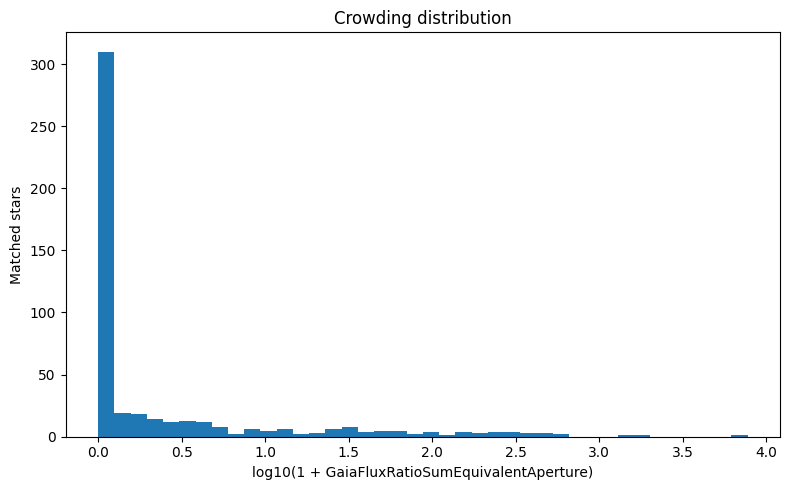

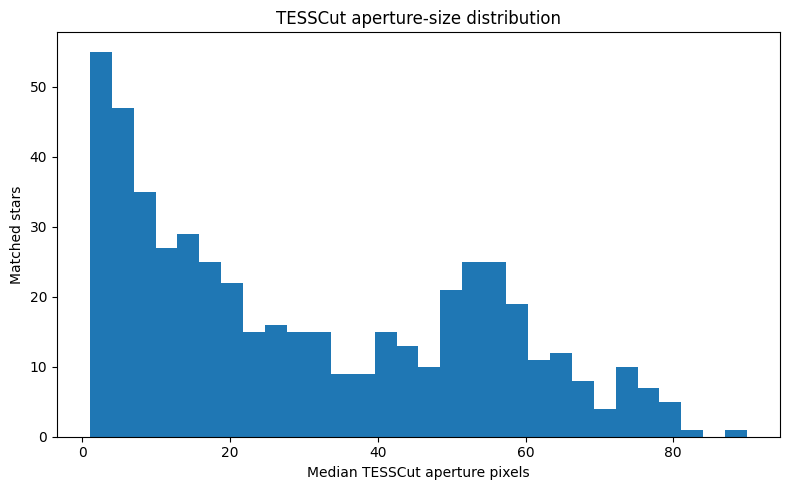

In [7]:
PRIMARY_CROWDING_METRIC = "GaiaFluxRatioSumEquivalentAperture"

if (
    PRIMARY_CROWDING_METRIC not in crowding.columns
    or crowding[PRIMARY_CROWDING_METRIC].notna().sum() < 100
):
    PRIMARY_CROWDING_METRIC = "GaiaFluxRatioSum1Pix"

print("Primary crowding metric:", PRIMARY_CROWDING_METRIC)

valid = pd.to_numeric(crowding[PRIMARY_CROWDING_METRIC], errors="coerce").dropna()

plt.figure(figsize=(8, 5))
plt.hist(np.log10(1.0 + valid), bins=40)
plt.xlabel(f"log10(1 + {PRIMARY_CROWDING_METRIC})")
plt.ylabel("Matched stars")
plt.title("Crowding distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(crowding["TESSCutAperturePixelsMedian"].dropna(), bins=30)
plt.xlabel("Median TESSCut aperture pixels")
plt.ylabel("Matched stars")
plt.title("TESSCut aperture-size distribution")
plt.tight_layout()
plt.show()

## 8. Revalidate the corrected matched feature table

The table was loaded before target construction. Check its scientific-fix manifest and eligibility again before fitting the models.


In [8]:
# Features were loaded, manifest-validated, and paired before Gaia handling.
# Recheck the extraction manifest to detect inputs changed during this run.
if (not trv.feature_cache_is_current(SPOC_TESSCut_FEATURE_FILE_QC)
        or loaded_feature_fingerprint != trv.file_fingerprints([SPOC_TESSCut_FEATURE_FILE_QC])):
    raise RuntimeError("Corrected feature file changed during the run. Restart this notebook after rerunning02.")
trv.assert_eligible(features)
trv.require_feature_schema(features)
if set(features["VSXId"]) != set(baseline_valid_ids):
    raise AssertionError("Feature cohort changed after baseline eligibility validation.")
print(f"Corrected eligible feature table: {len(features):,} rows x {len(features.columns)} columns")
display(features["_Provenance"].value_counts())


Corrected eligible feature table: 1,012 rows x 61 columns


_Provenance
SPOC       506
TESSCut    506
Name: count, dtype: int64

## 9. Recompute matched SPOC–TESSCut RF predictions

Fit fresh models using the frozen 39-predictor contract and identical corrected baseline IDs and star-level split assignments. The models use median imputation and 500 trees with balanced-subsample class weights. Saved old predictions and hardcoded manuscript performance targets are not reused.


In [9]:
MODEL_FEATURE_COLUMNS = trv.require_feature_schema(features)
trv.assert_eligible(features)

missing = sorted(set(MODEL_FEATURE_COLUMNS) - set(features.columns))
if missing:
    raise ValueError(f"Feature table missing controlled-model columns: {missing}")

assert len(MODEL_FEATURE_COLUMNS) == 39
assert "ProvenanceScore" not in MODEL_FEATURE_COLUMNS
print("Canonical model feature count:", len(MODEL_FEATURE_COLUMNS))
print("ProvenanceScore excluded:", "ProvenanceScore" not in MODEL_FEATURE_COLUMNS)


def provenance_features(name):
    df = features[features["_Provenance"] == name].copy()
    counts = df.groupby("VSXId").size()
    unique_ids = counts.index[counts == 1]
    return (
        df[df["VSXId"].isin(unique_ids)]
        .set_index("VSXId", drop=False)
        .sort_index()
    )


spoc_features = provenance_features("SPOC")
tc_features = provenance_features("TESSCut")

rf_ids = baseline_valid_ids
if set(crowding["VSXId"].astype(str)) != set(rf_ids):
    raise ValueError("Crowding rows do not cover every baseline-eligible star.")

spoc_features = spoc_features.loc[rf_ids]
tc_features = tc_features.loc[rf_ids]

if not (
    spoc_features[TARGET_COLUMN].astype(str).values
    == tc_features[TARGET_COLUMN].astype(str).values
).all():
    raise ValueError("SPOC and TESSCut family labels do not match.")

class_counts = spoc_features[TARGET_COLUMN].astype(str).value_counts()
keep_classes = class_counts[class_counts >= 2].index
keep_ids = spoc_features.index[
    spoc_features[TARGET_COLUMN].astype(str).isin(keep_classes)
].to_numpy()

train_ids, test_ids = train_test_split(
    keep_ids,
    test_size=TEST_SIZE,
    stratify=spoc_features.loc[keep_ids, TARGET_COLUMN],
    random_state=RANDOM_STATE,
)
train_ids = sorted(train_ids)
test_ids = sorted(test_ids)


def train_and_predict(source_df, label):
    train_df = source_df.loc[train_ids]
    test_df = source_df.loc[test_ids]

    X_train = train_df[MODEL_FEATURE_COLUMNS]
    y_train = train_df[TARGET_COLUMN].astype(str)
    X_test = test_df[MODEL_FEATURE_COLUMNS]
    y_test = test_df[TARGET_COLUMN].astype(str)

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    confidence = np.max(model.predict_proba(X_test), axis=1)

    return model, pd.DataFrame({
        "VSXId": test_ids,
        "TrueFamily": y_test.loc[test_ids].values,
        f"{label}Prediction": pred,
        f"{label}Correct": pred == y_test.loc[test_ids].values,
        f"{label}Confidence": confidence,
    })


spoc_model, spoc_test = train_and_predict(spoc_features, "SPOC")
tc_model, tc_test = train_and_predict(tc_features, "TESSCut")

test_results = spoc_test.merge(
    tc_test,
    on=["VSXId", "TrueFamily"],
    how="inner",
)

test_results["OutcomeCategory"] = np.select(
    [
        test_results["SPOCCorrect"] & test_results["TESSCutCorrect"],
        test_results["SPOCCorrect"] & ~test_results["TESSCutCorrect"],
        ~test_results["SPOCCorrect"] & test_results["TESSCutCorrect"],
    ],
    [
        "both_correct",
        "spoc_only_correct",
        "tesscut_only_correct",
    ],
    default="both_wrong",
)

crowding_merge = crowding.copy()
crowding_merge["VSXId"] = crowding_merge["VSXId"].astype(str)

test_results = test_results.merge(crowding_merge, on="VSXId", how="left")
test_results.to_parquet(RF_TEST_RESULTS_FILE, index=False)

print(f"Shared train stars: {len(train_ids):,}")
print(f"Shared test stars: {len(test_ids):,}")

SPOCAccuracy = float(test_results["SPOCCorrect"].mean())
TESSCutAccuracy = float(test_results["TESSCutCorrect"].mean())
SPOCBalancedAccuracy = float(
    balanced_accuracy_score(
        test_results["TrueFamily"],
        test_results["SPOCPrediction"],
    )
)
TESSCutBalancedAccuracy = float(
    balanced_accuracy_score(
        test_results["TrueFamily"],
        test_results["TESSCutPrediction"],
    )
)

print("SPOC accuracy:", f"{SPOCAccuracy:.6f}")
print("TESSCut accuracy:", f"{TESSCutAccuracy:.6f}")
print("SPOC balanced accuracy:", f"{SPOCBalancedAccuracy:.6f}")
print("TESSCut balanced accuracy:", f"{TESSCutBalancedAccuracy:.6f}")

# Record current corrected results; old manuscript accuracies are not assertions.
current_baseline_metrics = pd.DataFrame([
    {"Provenance": "SPOC", "MatchedStars": len(keep_ids), "TestStars": len(test_ids),
     "Accuracy": SPOCAccuracy, "BalancedAccuracy": SPOCBalancedAccuracy},
    {"Provenance": "TESSCut", "MatchedStars": len(keep_ids), "TestStars": len(test_ids),
     "Accuracy": TESSCutAccuracy, "BalancedAccuracy": TESSCutBalancedAccuracy},
])
current_baseline_metrics.to_csv(OUTPUT_DIR / "corrected_matched_baseline_metrics.csv", index=False)
display(current_baseline_metrics)

CROWDING_RUN_CONFIG = {
    "comparison": "SPOC_vs_TESSCut", "features": list(MODEL_FEATURE_COLUMNS),
    "seed": RANDOM_STATE, "test_size": TEST_SIZE,
    "rf_n_estimators": 500, "rf_class_weight": "balanced_subsample",
    "primary_crowding_metric": PRIMARY_CROWDING_METRIC,
    "gaia_query_radius_arcsec": GAIA_QUERY_RADIUS_ARCSEC,
    "gaia_g_max": GAIA_G_MAX,
    "gaia_target_match_radius_arcsec": GAIA_TARGET_MATCH_RADIUS_ARCSEC,
}

display(test_results["OutcomeCategory"].value_counts())


Canonical model feature count: 39
ProvenanceScore excluded: True
Shared train stars: 354
Shared test stars: 152
SPOC accuracy: 0.763158
TESSCut accuracy: 0.631579
SPOC balanced accuracy: 0.571473
TESSCut balanced accuracy: 0.386845


,Provenance,MatchedStars,TestStars,Accuracy,BalancedAccuracy
0,SPOC,506,152,0.763158,0.571473
1,TESSCut,506,152,0.631579,0.386845


OutcomeCategory
both_correct            85
spoc_only_correct       31
both_wrong              25
tesscut_only_correct    11
Name: count, dtype: int64

## 10. Performance gap across current crowding quartiles

Divide held-out stars with finite current crowding values into four rank-based quartiles. Recompute accuracy and balanced-accuracy gaps from the newly fitted paired predictions. Counts and gap values are generated below.


/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/jamesliang/.local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,CrowdingQuartile,Stars,CrowdingMedian,SPOCAccuracy,TESSCutAccuracy,AccuracyGap_SPOC_minus_TESSCut,SPOCBalancedAccuracy,TESSCutBalancedAccuracy,BalancedAccuracyGap_SPOC_minus_TESSCut,ScientificFixVersion
0,Q1 least crowded,37,0.000060,0.891892,0.756757,0.135135,0.703297,0.312088,0.391209,eligibility_fap_v1
1,Q2,37,0.010204,0.729730,0.594595,0.135135,0.543750,0.432986,0.110764,eligibility_fap_v1
2,Q3,37,0.218336,0.621622,0.486486,0.135135,0.480060,0.323810,0.156250,eligibility_fap_v1
3,Q4 most crowded,37,19.752412,0.810811,0.702703,0.108108,0.527778,0.407407,0.120370,eligibility_fap_v1


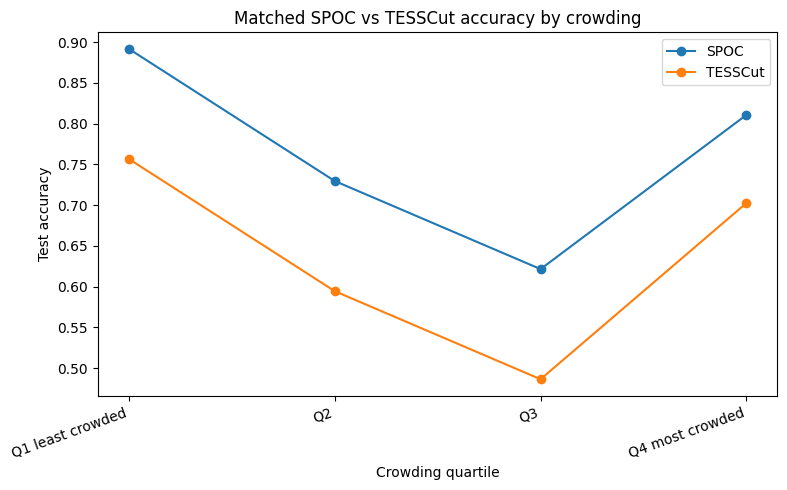

In [10]:
analysis_test = test_results.copy()
analysis_test["_Crowding"] = pd.to_numeric(
    analysis_test[PRIMARY_CROWDING_METRIC],
    errors="coerce",
)
analysis_test = analysis_test[np.isfinite(analysis_test["_Crowding"])].copy()

if len(analysis_test) < 4:
    raise ValueError("Fewer than four held-out stars have finite Gaia crowding. Restore usable saved Gaia coverage before quartile analysis.")

analysis_test["CrowdingQuartile"] = pd.qcut(
    analysis_test["_Crowding"].rank(method="first"),
    4,
    labels=["Q1 least crowded", "Q2", "Q3", "Q4 most crowded"],
)

rows = []
for quartile, group in analysis_test.groupby("CrowdingQuartile", observed=False):
    spoc_acc = float(group["SPOCCorrect"].mean())
    tc_acc = float(group["TESSCutCorrect"].mean())
    spoc_bal = float(
        balanced_accuracy_score(
            group["TrueFamily"],
            group["SPOCPrediction"],
        )
    )
    tc_bal = float(
        balanced_accuracy_score(
            group["TrueFamily"],
            group["TESSCutPrediction"],
        )
    )

    rows.append({
        "CrowdingQuartile": str(quartile),
        "Stars": len(group),
        "CrowdingMedian": float(group["_Crowding"].median()),
        "SPOCAccuracy": spoc_acc,
        "TESSCutAccuracy": tc_acc,
        "AccuracyGap_SPOC_minus_TESSCut": spoc_acc - tc_acc,
        "SPOCBalancedAccuracy": spoc_bal,
        "TESSCutBalancedAccuracy": tc_bal,
        "BalancedAccuracyGap_SPOC_minus_TESSCut": spoc_bal - tc_bal,
    })

quartile_performance = pd.DataFrame(rows)
quartile_performance["ScientificFixVersion"] = trv.SCIENCE_FIX_VERSION
display(quartile_performance)

quartile_performance.to_csv(
    OUTPUT_DIR / "accuracy_by_crowding_quartile.csv",
    index=False,
)

plt.figure(figsize=(8, 5))
x = np.arange(len(quartile_performance))
plt.plot(x, quartile_performance["SPOCAccuracy"], marker="o", label="SPOC")
plt.plot(x, quartile_performance["TESSCutAccuracy"], marker="o", label="TESSCut")
plt.xticks(x, quartile_performance["CrowdingQuartile"], rotation=20, ha="right")
plt.ylabel("Test accuracy")
plt.xlabel("Crowding quartile")
plt.title("Matched SPOC vs TESSCut accuracy by crowding")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Direct failure-pattern test

Compare current crowding values for stars classified correctly only by SPOC against stars correctly classified by both products. Compute the two-sided Mann–Whitney test only when both groups contain enough observations.


In [11]:
outcome_crowding = (
    analysis_test
    .groupby("OutcomeCategory")["_Crowding"]
    .agg(["count", "median", "mean"])
    .sort_values("median")
)
display(outcome_crowding)

a = analysis_test.loc[
    analysis_test["OutcomeCategory"] == "spoc_only_correct",
    "_Crowding",
].dropna()

b = analysis_test.loc[
    analysis_test["OutcomeCategory"] == "both_correct",
    "_Crowding",
].dropna()

if len(a) >= 5 and len(b) >= 5:
    mw = mannwhitneyu(a, b, alternative="two-sided")
    print("spoc_only_correct vs both_correct")
    print("U =", float(mw.statistic))
    print("p =", float(mw.pvalue))
    print("Median spoc_only_correct =", float(a.median()))
    print("Median both_correct =", float(b.median()))
else:
    print("Not enough stars for Mann–Whitney test.")

,count,median,mean
OutcomeCategory,,,
both_correct,83,0.025551,16.250984
spoc_only_correct,30,0.036317,21.548189
tesscut_only_correct,11,0.036407,7.444324
both_wrong,24,0.168220,10.071491


spoc_only_correct vs both_correct
U = 1223.0
p = 0.8888128276093811
Median spoc_only_correct = 0.0363167670485888
Median both_correct = 0.02555104025785713


## 12. Overall SPOC–TESSCut feature disagreement vs crowding

Use only the corrected baseline feature pairs. Scale each absolute product difference by its paired-sample IQR and take the per-star median across usable predictors. Recompute its Spearman association with current crowding measurements.


Crowding vs robust SPOC–TESSCut feature distance
N = 491
Spearman rho = 0.22726314314832494
p = 3.5857655985522046e-07


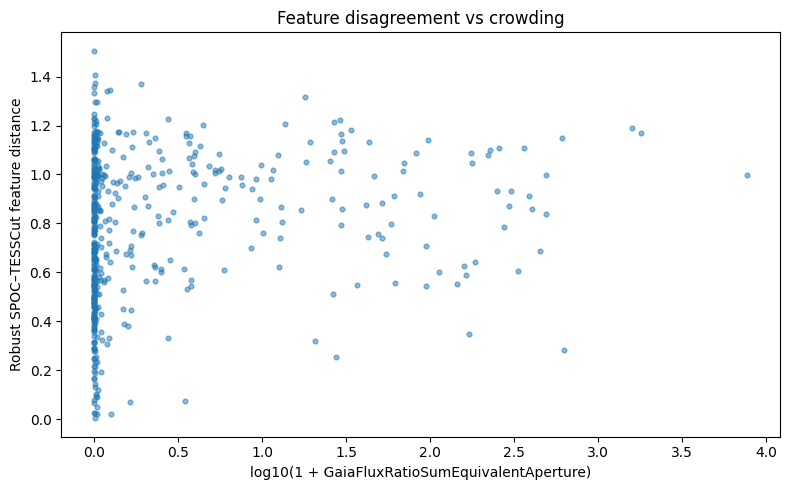

In [12]:
pair_ids = spoc_features.index.intersection(tc_features.index)

components = {}
for feature in MODEL_FEATURE_COLUMNS:
    q = pd.to_numeric(spoc_features.loc[pair_ids, feature], errors="coerce")
    t = pd.to_numeric(tc_features.loc[pair_ids, feature], errors="coerce")
    combined = pd.concat([q, t])
    iqr = combined.quantile(0.75) - combined.quantile(0.25)

    if np.isfinite(iqr) and iqr > 0:
        components[feature] = (q - t).abs() / iqr

component_df = pd.DataFrame(components, index=pair_ids)

feature_distance = (
    component_df.median(axis=1, skipna=True)
    .rename("RobustFeatureDistance_SPOC_TESSCut")
    .reset_index()
    .rename(columns={"index": "VSXId"})
)
feature_distance["VSXId"] = feature_distance["VSXId"].astype(str)

feature_crowding = feature_distance.merge(
    crowding_merge[["VSXId", PRIMARY_CROWDING_METRIC]],
    on="VSXId",
    how="inner",
)

cx = pd.to_numeric(feature_crowding[PRIMARY_CROWDING_METRIC], errors="coerce")
fy = pd.to_numeric(
    feature_crowding["RobustFeatureDistance_SPOC_TESSCut"],
    errors="coerce",
)
mask = np.isfinite(cx) & np.isfinite(fy)

overall_feature_distance_rho, overall_feature_distance_p = spearmanr(
    cx[mask],
    fy[mask],
)

print("Crowding vs robust SPOC–TESSCut feature distance")
print("N =", int(mask.sum()))
print("Spearman rho =", float(overall_feature_distance_rho))
print("p =", float(overall_feature_distance_p))

feature_crowding.to_parquet(
    OUTPUT_DIR / "feature_distance_vs_crowding.parquet",
    index=False,
)

plt.figure(figsize=(8, 5))
plt.scatter(np.log10(1 + cx[mask]), fy[mask], s=12, alpha=0.5)
plt.xlabel(f"log10(1 + {PRIMARY_CROWDING_METRIC})")
plt.ylabel("Robust SPOC–TESSCut feature distance")
plt.title("Feature disagreement vs crowding")
plt.tight_layout()
plt.show()

## 13. Feature-level and aperture associations

Recompute per-feature associations between absolute product differences and crowding, then examine aperture size and the combined crowding-times-aperture proxy separately. These per-feature comparisons are exploratory because multiple features are examined.


In [13]:
crowding_by_id = crowding_merge.set_index("VSXId")[PRIMARY_CROWDING_METRIC]

per_feature_rows = []
for feature in MODEL_FEATURE_COLUMNS:
    q = pd.to_numeric(spoc_features.loc[pair_ids, feature], errors="coerce")
    t = pd.to_numeric(tc_features.loc[pair_ids, feature], errors="coerce")
    d = (q - t).abs()
    c = pd.to_numeric(crowding_by_id.reindex(pair_ids), errors="coerce")
    valid = np.isfinite(d) & np.isfinite(c)

    if valid.sum() >= 30:
        r, p = spearmanr(c[valid], d[valid])
        per_feature_rows.append({
            "Feature": feature,
            "N": int(valid.sum()),
            "SpearmanRhoAbsDifferenceVsCrowding": float(r),
            "PValue": float(p),
        })

per_feature = pd.DataFrame(per_feature_rows, columns=[
    "Feature", "N", "SpearmanRhoAbsDifferenceVsCrowding", "PValue"
])
if len(per_feature):
    per_feature["AbsRho"] = per_feature["SpearmanRhoAbsDifferenceVsCrowding"].abs()
    per_feature = per_feature.sort_values("AbsRho", ascending=False)
    display(per_feature.head(15))
per_feature.to_csv(
    OUTPUT_DIR / "individual_feature_difference_crowding_spearman.csv", index=False,
)

aperture_feature = feature_distance.merge(
    crowding_merge[
        ["VSXId", PRIMARY_CROWDING_METRIC, "TESSCutAperturePixelsMedian"]
    ],
    on="VSXId",
    how="inner",
)

aperture_feature["CrowdingTimesAperture"] = (
    pd.to_numeric(aperture_feature[PRIMARY_CROWDING_METRIC], errors="coerce")
    * pd.to_numeric(aperture_feature["TESSCutAperturePixelsMedian"], errors="coerce")
)

print("\nSeparate aperture/crowding association tests:")

for metric in [
    "TESSCutAperturePixelsMedian",
    PRIMARY_CROWDING_METRIC,
    "CrowdingTimesAperture",
]:
    x = pd.to_numeric(aperture_feature[metric], errors="coerce")
    y = pd.to_numeric(
        aperture_feature["RobustFeatureDistance_SPOC_TESSCut"],
        errors="coerce",
    )
    valid = np.isfinite(x) & np.isfinite(y)

    if valid.sum() >= 30:
        r, p = spearmanr(x[valid], y[valid])
        print(
            f"{metric} vs feature distance: "
            f"N={int(valid.sum())}, rho={r:.3f}, p={p:.3g}"
        )

/tmp/ipykernel_3711574/1857354557.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = spearmanr(c[valid], d[valid])


,Feature,N,SpearmanRhoAbsDifferenceVsCrowding,PValue,AbsRho
21,MedianAbsSuccessiveDiff,491,0.439819,1.209882e-24,0.439819
19,EtaVonNeumann,491,0.353168,7.196015e-16,0.353168
2,OriginalFluxStd,491,0.294310,2.876442e-11,0.294310
18,TailRatio,491,0.291487,4.518060e-11,0.291487
8,FluxMad,491,0.210664,2.488610e-06,0.210664
12,FluxIqr,491,0.196510,1.153911e-05,0.196510
26,LsFalseAlarmProbability,491,0.183019,4.511395e-05,0.183019
1,OriginalFluxMedian,491,0.167413,1.941567e-04,0.167413
3,CadenceCount,491,-0.162515,2.992015e-04,0.162515
0,QualityScore,491,-0.155911,5.259570e-04,0.155911



Separate aperture/crowding association tests:
TESSCutAperturePixelsMedian vs feature distance: N=506, rho=-0.288, p=3.92e-11
GaiaFluxRatioSumEquivalentAperture vs feature distance: N=491, rho=0.227, p=3.59e-07
CrowdingTimesAperture vs feature distance: N=491, rho=0.201, p=7.53e-06


## 14. Interpretation after the corrected rerun

Use the new quartile gaps, outcome-group comparison, and feature-distance associations to assess the evidence. Do not carry over previous numerical values or causal conclusions. Missing Gaia crowding measurements affect association-test coverage, while the matched RF sample is determined by baseline feature eligibility.


In [14]:
summary_rows = []

if len(quartile_performance):
    first = quartile_performance.iloc[0]
    last = quartile_performance.iloc[-1]
    summary_rows.append({
        "Metric": "SPOC-TESSCut accuracy gap, least crowded quartile",
        "Value": float(first["AccuracyGap_SPOC_minus_TESSCut"]),
    })
    summary_rows.append({
        "Metric": "SPOC-TESSCut accuracy gap, most crowded quartile",
        "Value": float(last["AccuracyGap_SPOC_minus_TESSCut"]),
    })
    summary_rows.append({
        "Metric": "Change in accuracy gap Q4-Q1",
        "Value": float(
            last["AccuracyGap_SPOC_minus_TESSCut"]
            - first["AccuracyGap_SPOC_minus_TESSCut"]
        ),
    })

    summary_rows.append({
        "Metric": "SPOC-TESSCut balanced-accuracy gap, least crowded quartile",
        "Value": float(first["BalancedAccuracyGap_SPOC_minus_TESSCut"]),
    })
    summary_rows.append({
        "Metric": "SPOC-TESSCut balanced-accuracy gap, most crowded quartile",
        "Value": float(last["BalancedAccuracyGap_SPOC_minus_TESSCut"]),
    })
    summary_rows.append({
        "Metric": "Change in balanced-accuracy gap Q4-Q1",
        "Value": float(
            last["BalancedAccuracyGap_SPOC_minus_TESSCut"]
            - first["BalancedAccuracyGap_SPOC_minus_TESSCut"]
        ),
    })

summary_rows.append({
    "Metric": "Spearman crowding vs robust feature distance",
    "Value": float(overall_feature_distance_rho),
})
summary_rows.append({
    "Metric": "Spearman p-value",
    "Value": float(overall_feature_distance_p),
})

summary = pd.DataFrame(summary_rows)
display(summary)

summary.to_csv(
    OUTPUT_DIR / "primary_crowding_experiment_summary.csv",
    index=False,
)

print("All outputs saved under:")
print(OUTPUT_DIR)
# Bind all derived results to current corrected features, preserved metadata,
# saved Gaia neighbors, and the fixed predictor/model contract.
if trv.file_fingerprints(CROWDING_RUN_INPUTS) != CROWDING_RUN_INPUT_FINGERPRINTS:
    raise RuntimeError("Crowding inputs changed during execution. Restart and rerun this notebook.")
trv.write_run_manifest(
    CROWDING_RUN_MANIFEST, inputs=CROWDING_RUN_INPUTS,
    config=CROWDING_RUN_CONFIG, outputs=CROWDING_RUN_OUTPUTS,
)
print("Current scientific-run manifest:", CROWDING_RUN_MANIFEST)


,Metric,Value
0,"SPOC-TESSCut accuracy gap, least crowded quartile",1.351351e-01
1,"SPOC-TESSCut accuracy gap, most crowded quartile",1.081081e-01
2,Change in accuracy gap Q4-Q1,-2.702703e-02
3,"SPOC-TESSCut balanced-accuracy gap, least crow...",3.912088e-01
4,"SPOC-TESSCut balanced-accuracy gap, most crowd...",1.203704e-01
5,Change in balanced-accuracy gap Q4-Q1,-2.708384e-01
6,Spearman crowding vs robust feature distance,2.272631e-01
7,Spearman p-value,3.585766e-07


All outputs saved under:
/data/projects/TESS_Research_Publication/results/crowding/spoc
Current scientific-run manifest: /data/projects/TESS_Research_Publication/results/crowding/spoc/crowding_science_fix_run.json


## Current-run result summary

The tables below are tied to corrected feature inputs, cached Gaia data, and the fixed predictor/model settings. The scientific-run manifest validates those inputs and all derived outputs before publication-figure export. Update the manuscript from this rerun after inspecting its results.


## Export the current crowding-gap figure

Read only the new CSV after validating its run manifest against corrected features and saved Gaia inputs. Export a 600-dpi PNG preview and a vector PDF with embedded fonts. Old snapshots and stale CSV files are rejected.


In [ ]:
# Export publication artwork from validated current CSV only.
import tess_research_validation as trv
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

SAVED_RESULTS_DIR = Project_Root / "results" / "crowding" / "spoc"
QUARTILE_CSV = SAVED_RESULTS_DIR / "accuracy_by_crowding_quartile.csv"
RUN_MANIFEST = SAVED_RESULTS_DIR / "crowding_science_fix_run.json"
if not QUARTILE_CSV.is_file() or not RUN_MANIFEST.is_file():
    raise FileNotFoundError("Run the corrected crowding analysis first; current CSV/manifest is missing.")
run_config = json.loads(RUN_MANIFEST.read_text())["config"]
if run_config.get("features") != list(trv.FEATURE_COLUMNS) or run_config.get("seed") != RANDOM_STATE:
    raise RuntimeError("Saved crowding predictor/split contract is stale. Rerun this notebook.")
trv.read_corrected_features(SPOC_TESSCut_FEATURE_FILE_QC)
if not trv.run_cache_is_current(
    RUN_MANIFEST, inputs=CROWDING_RUN_INPUTS, config=run_config,
    outputs=CROWDING_RUN_OUTPUTS,
):
    raise RuntimeError("Saved crowding results do not match current corrected inputs. Rerun this notebook.")
saved_quartiles = pd.read_csv(QUARTILE_CSV)
required = ["CrowdingQuartile", "Stars", "AccuracyGap_SPOC_minus_TESSCut", "BalancedAccuracyGap_SPOC_minus_TESSCut"]
if not set(required).issubset(saved_quartiles.columns):
    raise ValueError("Current quartile CSV is missing required fields.")
if len(saved_quartiles) !=4 or saved_quartiles[required].isna().any().any():
    raise ValueError("Expected four complete current crowding-quartile rows.")
if not saved_quartiles["ScientificFixVersion"].eq(trv.SCIENCE_FIX_VERSION).all():
    raise ValueError("Quartile CSV predates the scientific fix.")
with plt.rc_context({
    "pdf.fonttype": 42,
    "font.family": "DejaVu Sans",
    "font.size": 8.2,
    "axes.labelsize": 8.2,
    "xtick.labelsize": 8.2,
    "ytick.labelsize": 8.2,
    "legend.fontsize": 8.2,
    "savefig.bbox": None,
}):
    x = range(len(saved_quartiles))
    fig, ax = plt.subplots(figsize=(3.1, 2.4))
    ax.plot(
        x, 100 * saved_quartiles["AccuracyGap_SPOC_minus_TESSCut"],
        marker="o", label="Accuracy",
    )
    ax.plot(
        x, 100 * saved_quartiles["BalancedAccuracyGap_SPOC_minus_TESSCut"],
        marker="s", label="Balanced accuracy",
    )
    labels = [
        f"{str(quartile).split()[0]}\n(n={int(count)})"
        for quartile, count in zip(saved_quartiles["CrowdingQuartile"], saved_quartiles["Stars"])
    ]
    ax.set_xticks(list(x), labels)
    ax.set_xlabel("Crowding quartile")
    ax.set_ylabel("SPOC minus TESSCut\n(percentage points)")
    ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
    ax.legend(
        loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
        frameon=False, columnspacing=1, handlelength=1.5,
    )
    fig.tight_layout(pad=0.7)
    stem = "crowding_quartile_gaps_spoc_section8"
    fig.savefig(SAVED_RESULTS_DIR / f"{stem}.png", dpi=600, bbox_inches=None)
    fig.savefig(SAVED_RESULTS_DIR / f"{stem}.pdf", bbox_inches=None)
    plt.show()
    plt.close(fig)
print("Vector artwork source:",QUARTILE_CSV)
display(saved_quartiles[required])
